# plotting v3_2 output

In [1]:
import sys
import math
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset # !! new - building netcdf
import os # file saving 
import xarray as xr
from pathlib import Path
import importlib.util
from glob import glob
import seaborn as sns
import imageio 
import tempfile

# v3_1

### not useful plot

In [ ]:
save_loc_v3_1 = "/gws/ssde/j25a/dcmex/users/ezriab/graupel_model_output/model_output_v3_2/" # location to save output files
save_name = 'ctrl'
ncfile = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", decode_times=False)
ncfile_envi = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="environment", engine="netcdf4",decode_times=False)
ncfile_ice = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="ice_particles", engine="netcdf4",decode_times=False)
ncfile_splinter = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="splinter_particles", engine="netcdf4",decode_times=False)

# also pull out the variables put into the namelist file
namelist_file = ncfile.attrs["namelist_file"]
with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist)

## pull out relevent functions
sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz

/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


FileNotFoundError: [Errno 2] No such file or directory: '/home/users/esree/simple-graupel-model/namelist.txt'

In [5]:
zbase = ptz(namelist['pbase']) # height of cloud base (m)
zbase

2951.706425601365

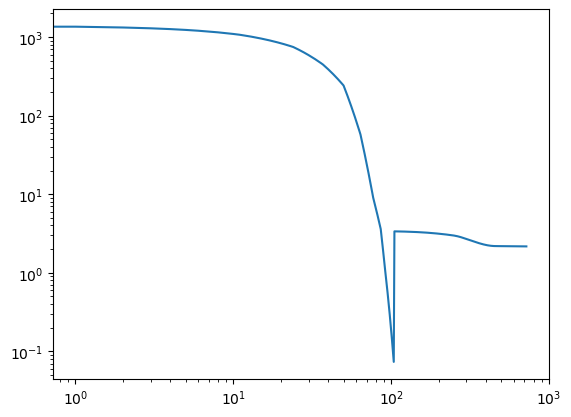

In [3]:
part_0 = ncfile_ice.isel(particle=0)
#part_0
plt.plot(part_0['concentration'])
plt.yscale('log')
plt.xscale('log')

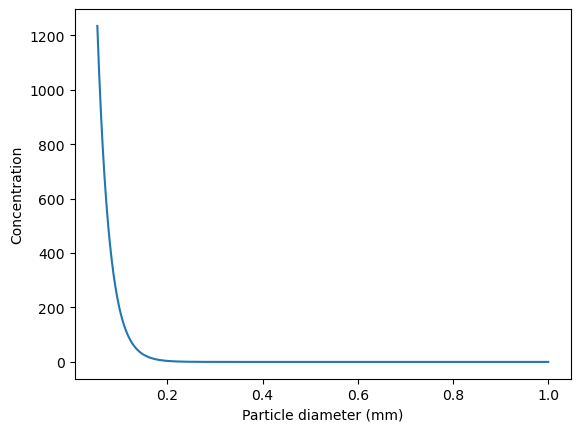

In [4]:
import numpy as np
import matplotlib.pyplot as plt

dmm = np.linspace(0.053, 1.0, 500)  # diameter in mm


conc_n = 10**4 * np.exp(-39.47 * dmm)

plt.plot(dmm, conc_n)

plt.xlabel("Particle diameter (mm)")
plt.ylabel("Concentration")
plt.show()

In [6]:
ncfile

<xarray.Dataset> Size: 9kB
Dimensions:            (time: 721, height: 1500, particle: 20,
                        splinter_particle: 59)
Coordinates:
  * time               (time) float32 3kB 0.0 5.0 10.0 ... 3.595e+03 3.6e+03
  * height             (height) float32 6kB 0.0 10.0 ... 1.498e+04 1.499e+04
  * particle           (particle) int32 80B 0 0 0 0 0 0 0 0 ... 1 1 1 1 1 2 2 2
  * splinter_particle  (splinter_particle) int32 236B 0 1 2 3 4 ... 55 56 57 58
Data variables:
    *empty*
Attributes:
    pyfile_name:    /home/users/esree/simple-graupel-model/graupel_model_new_...
    namelist_file:  /home/users/esree/simple-graupel-model/namelist.txt

Text(0, 0.5, 'altitude (m)')

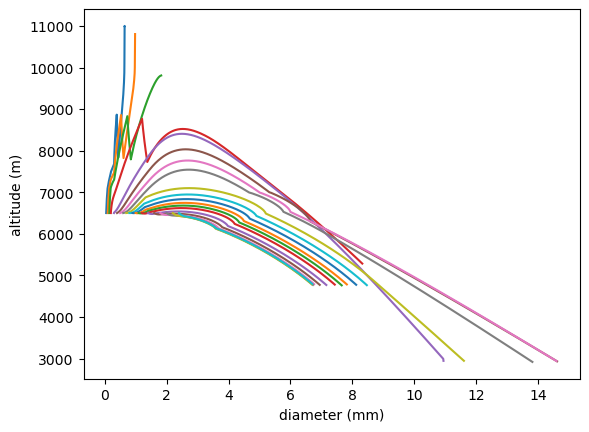

In [15]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    #plt.plot(ncfile['time']/60, p0_ice['diameter']*1000)
    plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])

plt.xlabel("diameter (mm)")
plt.ylabel("altitude (m)")


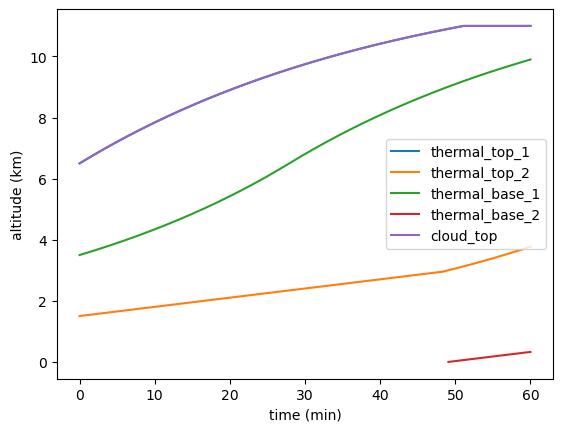

In [ ]:
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_top_1'], label='thermal_top_1')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_top_2'], label='thermal_top_2')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_base_1'], label='thermal_base_1')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_base_2'], label='thermal_base_2')
plt.plot(ncfile['time']/60, ncfile_envi['cloud_top'], label='cloud_top')
plt.plot(ncfile['time']/60, ncfile_envi['cloud_top'], label='cloud_top')

plt.ylabel("altitude (km)")
plt.xlabel("time (min)")
plt.legend()

### useful

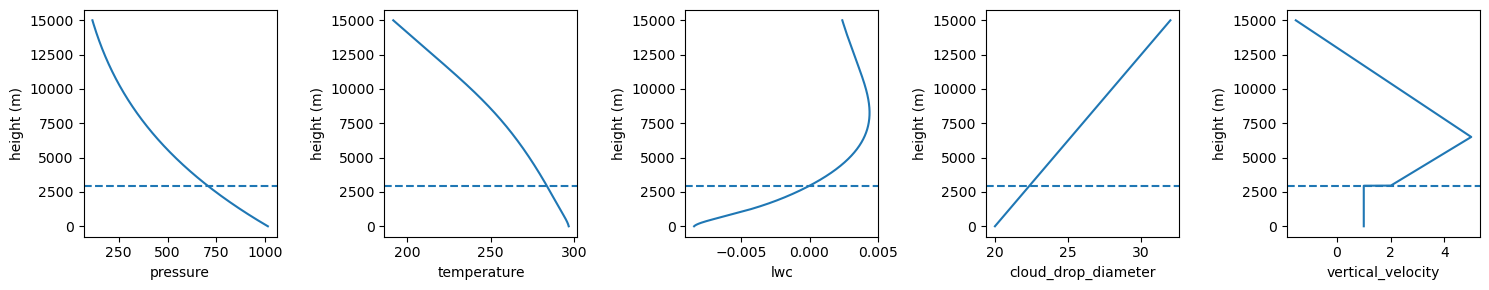

In [7]:
height_vars = ['pressure', 'temperature', 'lwc', 'cloud_drop_diameter', 'vertical_velocity']

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, ax in enumerate(axes):

    ax.plot(ncfile_envi[height_vars[i]], ncfile['height'])

    ax.axhline(
        y=zbase,
        linestyle="--",
        label=f"zbase = {zbase} m"
    )

    ax.set_xlabel(height_vars[i])
    ax.set_ylabel("height (m)")

plt.tight_layout()
plt.show()


# v3_2


In [23]:
save_loc_v3_2 = "/gws/ssde/j25a/dcmex/users/ezriab/graupel_model_output/model_output_v3_2/" # location to save output files
save_loc_v3_2 = "/gws/ssde/j25a/dcmex/users/ezriab/graupel_model_output/v3_2/"
save_name = 'blyth_latham_thermal_test_umax2'#'blyth_latham_og_zct0_umax2_diam_thermal'#'blyth_latham_og_zct0_umax2_diam'
#'blyth_latham_og_zct0_umax2_alt_change'#'blyth_latham_og_zct0_umax2'#'blyth_latham_tdepth2'#'blyth_latham_vv2'#'blyth_latham_tdepth2km'#'blyth_latham_gentop' #'blyth_latham'
ncfile = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", decode_times=False)
ncfile_envi = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", group="environment", engine="netcdf4",decode_times=False)
ncfile_ice = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", group="ice_particles", engine="netcdf4",decode_times=False)
ncfile_splinter = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", group="splinter_particles", engine="netcdf4",decode_times=False)

# also pull out the variables put into the namelist file
namelist_file = ncfile.attrs["namelist_file"]
with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist)

## pull out relevent functions
sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz

In [3]:
namelist['CTOP']

8.0

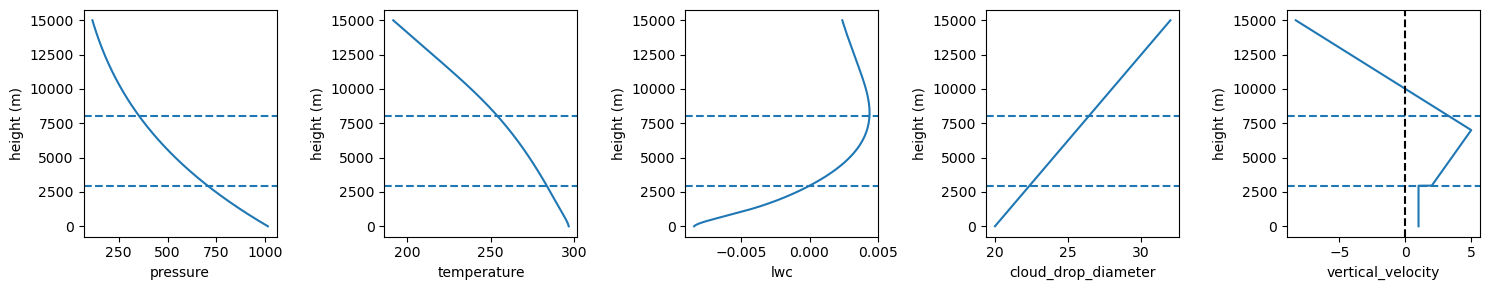

In [24]:
height_vars = ['pressure', 'temperature', 'lwc', 'cloud_drop_diameter', 'vertical_velocity']
zbase = ptz(namelist['pbase']) # height of cloud base (m)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, ax in enumerate(axes):

    ax.plot(ncfile_envi[height_vars[i]], ncfile['height'])

    ax.axhline(
        y=zbase,
        linestyle="--",
        label=f"zbase = {zbase} m")

    ax.axhline(
            y=namelist['CTOP']*1000,
            linestyle="--",
            label=f"CTOP = {namelist['CTOP']} m")

    ax.set_xlabel(height_vars[i])
    ax.set_ylabel("height (m)")
    if height_vars[i] == 'vertical_velocity':
        plt.axvline(x=0, color='black', linestyle='--', label='TWID')


plt.tight_layout()
plt.show()


(0.0, 85.0)

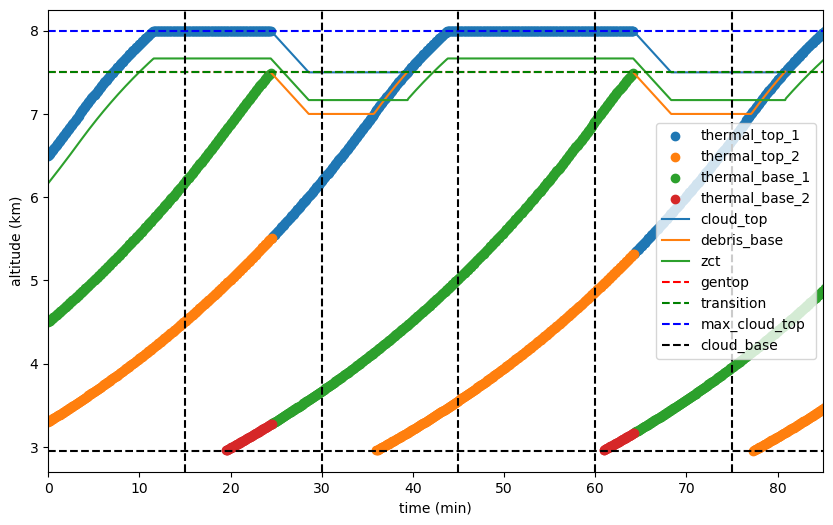

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))
#time = np.arange(0, len(thtop1)) * namelist['DELTIM'] / 60

plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_1'], label='thermal_top_1')
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_2'], label='thermal_top_2')
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_1'], label='thermal_base_1')
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_2'], label='thermal_base_2')

plt.plot(ncfile['time']/60, ncfile_envi['cloud_top'], label='cloud_top')
plt.plot(ncfile['time']/60, ncfile_envi['debris_base'], label='debris_base')
zbase = ptz(namelist['pbase']) # height of cloud base (m)
thbase_transition = namelist['CTOP'] - namelist['TDEPTH'] / 4.
GENCTOP = namelist['GENCTOP'] # height of cloud top (m)
CTOP = namelist['CTOP'] # height of cloud top (m)
ZCT = namelist['ZCT'] # height of cloud top (m)
ZCT_values = [v - ZCT for v in ncfile_envi['cloud_top']]
plt.plot(ncfile['time']/60, ZCT_values, label='zct')
plt.axhline(y=GENCTOP, color='r', linestyle='--', label='gentop')
plt.axhline(y=thbase_transition, color='g', linestyle='--', label='transition')
plt.axhline(y=CTOP, color='b', linestyle='--', label='max_cloud_top')
plt.axhline(y=zbase/1000, color='k', linestyle='--', label='cloud_base')

plt.axvline(x=15, color='black', linestyle='--')
plt.axvline(x=30, color='black', linestyle='--')
plt.axvline(x=45, color='black', linestyle='--')
plt.axvline(x=60, color='black', linestyle='--')
plt.axvline(x=75, color='black', linestyle='--')
plt.ylabel("altitude (km)")
plt.xlabel("time (min)")
plt.legend()
#plt.ylim(0, 12)
plt.xlim(0,85)

(0.0, 85.0)

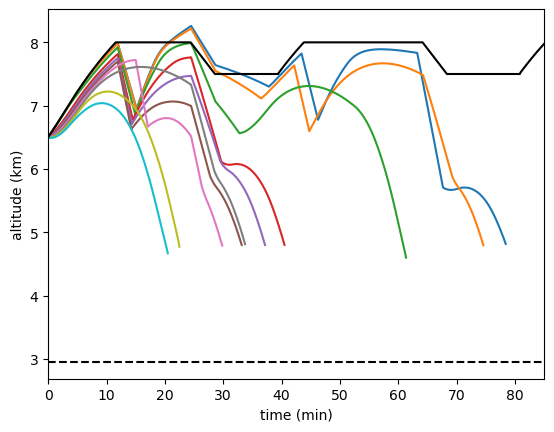

In [26]:
for s in range(ncfile_ice.sizes['particle']):
#for s in range(5):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    #plt.plot(ncfile['time']/60, p0_ice['diameter']*1000)
    #plt.plot(ncfile['time']/60, p0_ice['surface_temperature'])
    plt.plot(ncfile['time']/60, p0_ice['altitude']/1000)

#plt.plot(ncfile['time']/60, ncfile_envi['thermal_top_1'], label='thermal_top_1')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_top_2'], label='thermal_top_2')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_base_1'], label='thermal_base_1')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_base_2'], label='thermal_base_2')
plt.plot(ncfile['time']/60, ncfile_envi['cloud_top'],color='black', label='cloud_top')
#plt.plot(ncfile['time']/60, ncfile_envi['debris_base'], label='debris_base')

zbase = ptz(namelist['pbase']) # height of cloud base (m)
plt.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base')

plt.xlabel("time (min)")
plt.ylabel("altitude (km)")
plt.xlim(0, 85)

Text(0, 0.5, 'altitude (km)')

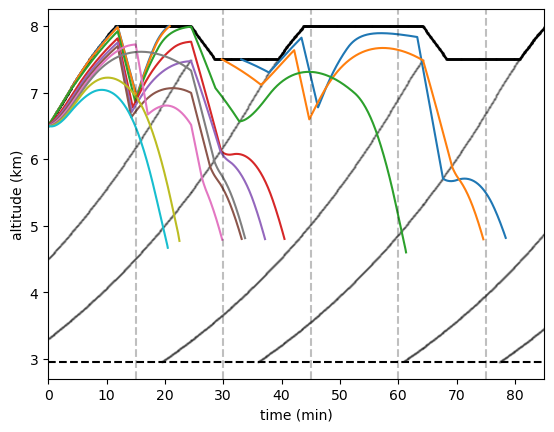

In [29]:
cloud_top = ncfile_envi['cloud_top']

mask_above_cloud = True

for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    altitude = p0_ice['altitude'] / 1000  # km
    if mask_above_cloud:
        # Mask particle altitude above cloud top
        altitude_masked = altitude.where(altitude <= cloud_top)
        plt.plot(ncfile['time'] / 60, altitude_masked)
    else:
        plt.plot(ncfile['time']/60, p0_ice['altitude']/1000)

plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_1'], label='thermal_top_1', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_2'], label='thermal_top_2', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_1'], label='thermal_base_1', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_2'], label='thermal_base_2', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['cloud_top'],color='black', label='cloud_top', s= 0.5)

plt.axvline(x=15, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=30, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=45, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=60, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=75, color='black', linestyle='--', alpha=0.25)


zbase = ptz(namelist['pbase']) # height of cloud base (m)
plt.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base')
plt.xlim(0, 85)
plt.xlabel("time (min)")
plt.ylabel("altitude (km)")

In [21]:
ncfile_envi

<xarray.Dataset> Size: 59kB
Dimensions:              (height: 1500, time: 1201)
Dimensions without coordinates: height, time
Data variables:
    pressure             (height) float32 6kB 1.013e+03 1.012e+03 ... 115.5
    temperature          (height) float32 6kB 296.9 296.9 296.9 ... 191.7 191.6
    lwc                  (height) float32 6kB -0.008475 -0.008465 ... 0.002409
    cloud_drop_diameter  (height) float32 6kB 20.0 20.01 20.02 ... 31.98 31.99
    vertical_velocity    (height) float32 6kB 1.0 1.0 1.0 ... -8.283 -8.3 -8.317
    thermal_top_1        (time) float32 5kB 6.5 6.512 6.523 ... 8.0 8.0 8.0
    thermal_base_1       (time) float32 5kB 4.5 4.508 4.516 ... 6.697 6.709
    thermal_top_2        (time) float32 5kB 3.3 3.308 3.314 ... 4.715 4.724
    thermal_base_2       (time) float32 5kB nan nan nan nan ... nan nan nan nan
    cloud_top            (time) float32 5kB 6.5 6.512 6.523 ... 8.0 8.0 8.0
    debris_base          (time) float32 5kB nan nan nan nan ... nan nan nan nan

Text(0, 0.5, 'altitude (km)')

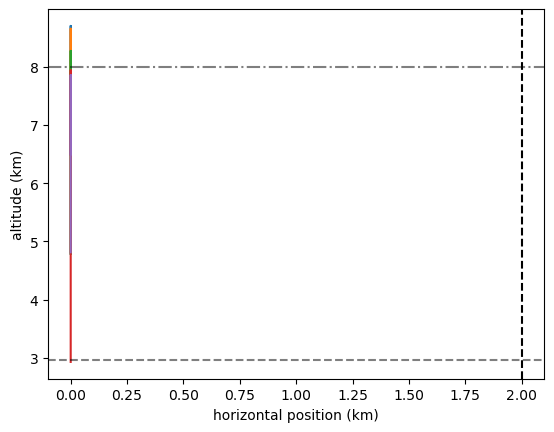

In [20]:
ncfile_envi

for s in range(5):
    p0_ice = ncfile_ice.isel(particle=s)
    plt.plot(p0_ice['horizontal_position'], p0_ice['altitude']/1000)

plt.axvline(x=namelist['TWID'], color='black', linestyle='--', label='TWID')
plt.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base',alpha=0.5)
plt.axhline(y=namelist['CTOP'], color='black', linestyle='-.', label='CTOP', alpha=0.5)

plt.xlabel("horizontal position (km)")
plt.ylabel("altitude (km)")

In [43]:
'''
ncfile_mins = ncfile['time'].values/60
plt.plot(ncfile_mins[:1000])
ncfile_ice.sizes['time']#[:1000]

for s in range(5):
    value = ncfile['time'].isel(time=s)
    print(value.values)
'''

t0_ice = ncfile_ice.isel(time=0)

print(ncfile_ice.sizes)
print(t0_ice['horizontal_position'].values[:10])
print(t0_ice['altitude'].values[:10])

for s in range(5):
    p0_ice = t0_ice.isel(particle=s)

Frozen({'particle': 20, 'time': 2401})
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[6500. 6500. 6500. 6500. 6500. 6500. 6500. 6500. 6500. 6500.]


In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
time = np.arange(0, len(thtop1)) * namelist['DELTIM'] / 60

plt.scatter(time, thtop1, label='thermal_top_1')
plt.scatter(time, thtop2, label='thermal_top_2')
plt.scatter(time, thbase1, label='thermal_base_1')
plt.scatter(time, thbase2, label='thermal_base_2')

plt.plot(time, cldtop, label='cloud_top')
plt.plot(time, downbase, label='debris_base')
zbase = ptz(namelist['pbase']) # height of cloud base (m)
thbase_transition = namelist['CTOP'] - namelist['TDEPTH'] / 4.
GENCTOP = namelist['GENCTOP'] # height of cloud top (m)
CTOP = namelist['CTOP'] # height of cloud top (m)
ZCT = namelist['ZCT'] # height of cloud top (m)
ZCT_values = [v - ZCT for v in cldtop]
plt.plot(time, ZCT_values, label='zct')
plt.axhline(y=GENCTOP, color='r', linestyle='--', label='gentop')
plt.axhline(y=thbase_transition, color='g', linestyle='--', label='transition')
plt.axhline(y=CTOP, color='b', linestyle='--', label='max_cloud_top')
plt.axhline(y=zbase/1000, color='k', linestyle='--', label='cloud_base')

plt.ylabel("altitude (km)")
plt.xlabel("time (min)")
plt.legend()
#plt.ylim(0, 12)

<xarray.Dataset> Size: 88kB
Dimensions:              (height: 1500, time: 2401)
Dimensions without coordinates: height, time
Data variables:
    pressure             (height) float32 6kB ...
    temperature          (height) float32 6kB ...
    lwc                  (height) float32 6kB ...
    cloud_drop_diameter  (height) float32 6kB ...
    vertical_velocity    (height) float32 6kB ...
    thermal_top_1        (time) float32 10kB 6.5 6.525 6.55 ... 4.519 4.536
    thermal_base_1       (time) float32 10kB ...
    thermal_top_2        (time) float32 10kB ...
    thermal_base_2       (time) float32 10kB ...
    cloud_top            (time) float32 10kB 6.5 6.525 6.55 ... 5.31 5.3 5.29
    debris_base          (time) float32 10kB ...

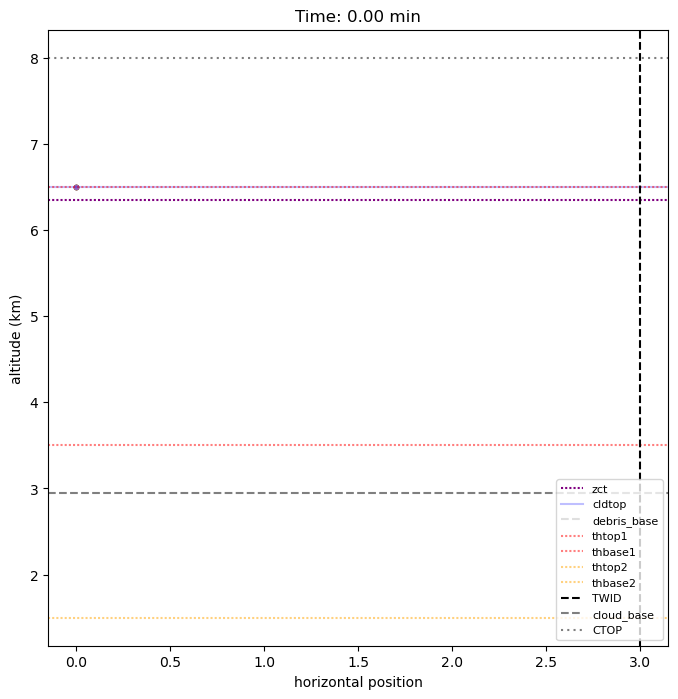

In [14]:
fig, ax = plt.subplots(figsize=(8, 8))
zbase = ptz(namelist['pbase']) # height of cloud base (m)

thtop_1 = ncfile_envi['thermal_top_1']
cldtop = ncfile_envi['cloud_top']
same = np.isclose(thtop_1.values, cldtop.values, equal_nan=False)
zct = thtop_1 - namelist['ZCT']
zct_matched = zct.where(same)
for t in range(1):
    for s in range(min(5, ncfile_ice.sizes['particle'])):
        p0_ice = ncfile_ice.isel(time=0, particle=s)
        value = ncfile['time'].isel(time=t)

        x = p0_ice['horizontal_position'].values
        z = p0_ice['altitude'].values / 1000
        ax.plot(x, z, marker='.')

    ## plot all thermals / debris base
    plt.axhline(y=zct_matched.isel(time=t), color='purple', linestyle=(0, (1, 1)), label='zct')
    
    plt.axhline(y= ncfile_envi['cloud_top'].isel(time=t), color='blue', linestyle='solid', label='cldtop', alpha=0.25)
    plt.axhline(y= ncfile_envi['debris_base'].isel(time=t), color='grey', linestyle='--', label='debris_base', alpha=0.25)
    plt.axhline(y= ncfile_envi['thermal_top_1'].isel(time=t), color='red', linestyle=(0, (1, 1)), label='thtop1', alpha=0.5)
    plt.axhline(y= ncfile_envi['thermal_base_1'].isel(time=t), color='red', linestyle=(0, (1, 1)), label='thbase1', alpha=0.5)
    plt.axhline(y= ncfile_envi['thermal_top_2'].isel(time=t), color='orange', linestyle=(0, (1, 1)), label='thtop2', alpha=0.5)
    plt.axhline(y= ncfile_envi['thermal_base_2'].isel(time=t), color='orange', linestyle=(0, (1, 1)), label='thbase2', alpha=0.5)

plt.title(f"Time: {value.values/60:.2f} min")
ax.set_xlabel("horizontal position")
ax.set_ylabel("altitude (km)")

plt.axvline(x=namelist['TWID'], color='black', linestyle='--', label='TWID')
plt.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base',alpha=0.5)
plt.axhline(y=namelist['CTOP'], color='black', linestyle=(0, (1, 2)), label='CTOP', alpha=0.5)
plt.legend(loc='lower right', fontsize=8)

plt.show()

In [ ]:
# make a gif of this through time
specif_save_folder = './'
ncfile_mins = ncfile['time'].values/60
zbase = ptz(namelist['pbase']) # height of cloud base (m)

with tempfile.TemporaryDirectory(dir=specif_save_folder, prefix="tmp_") as tmp_dir:
    frame_files = []
    for t in range(1000):#just first 1000 time steps ncfile_ice.sizes['time'][:1000]):
        frame_path = os.path.join(tmp_dir, f"frame_{t:04d}.png") # unique filenames
        t0_ice = ncfile_ice.isel(time=t)
        value = ncfile['time'].isel(time=t)
        
        fig = plt.figure(figsize=(8, 8))

        for s in range(5):
            p0_ice = t0_ice.isel(particle=s)
            plt.scatter(p0_ice['horizontal_position'], p0_ice['altitude']/1000)

        plt.axvline(x=namelist['TWID'], color='black', linestyle='--', label='TWID')
        plt.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base',alpha=0.5)
        plt.axhline(y=namelist['CTOP'], color='black', linestyle='-.', label='CTOP', alpha=0.5)

        plt.xlabel("horizontal position (km)")
        plt.ylabel("altitude (km)")
        plt.ylim(0, 9)
        plt.xlim(-0.5, 3.5)
        plt.title(f"Time: {value.values:.2f} s")

        plt.savefig(frame_path, bbox_inches='tight')

        plt.close()
        frame_files.append(frame_path) # all frames path

    frames = [imageio.v2.imread(f) for f in frame_files]

    gif_save_name = f'blerg'

    gif_path = os.path.join(specif_save_folder, f'{gif_save_name}.gif')
    imageio.mimsave(gif_path, frames, fps=5)
        

In [14]:


thtop_1 = ncfile_envi['thermal_top_1'].values
cldtop = ncfile_envi['cloud_top'].values


# Boolean mask where values are equal
same = thtop_1 == cldtop
indices = np.where(same)

# Get the matching values
matching_values = thtop_1[same]
matching_values.plot()

AttributeError: 'numpy.ndarray' object has no attribute 'plot'

In [10]:
ncfile_envi

<xarray.Dataset> Size: 88kB
Dimensions:              (height: 1500, time: 2401)
Dimensions without coordinates: height, time
Data variables:
    pressure             (height) float32 6kB ...
    temperature          (height) float32 6kB ...
    lwc                  (height) float32 6kB ...
    cloud_drop_diameter  (height) float32 6kB ...
    vertical_velocity    (height) float32 6kB ...
    thermal_top_1        (time) float32 10kB ...
    thermal_base_1       (time) float32 10kB ...
    thermal_top_2        (time) float32 10kB ...
    thermal_base_2       (time) float32 10kB ...
    cloud_top            (time) float32 10kB ...
    debris_base          (time) float32 10kB ...

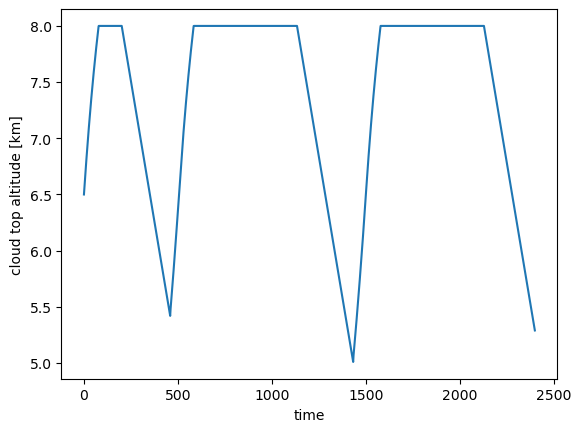

In [ ]:
#non_nan_surface = p0_ice['surface_temperature'].values[~np.isnan(p0_ice['surface_temperature'].values)]
#non_nan_surface

ncfile_envi['cloud_top'].plot()



In [6]:
ncfile_ice

<xarray.Dataset> Size: 519kB
Dimensions:              (particle: 20, time: 721)
Dimensions without coordinates: particle, time
Data variables:
    diameter             (particle, time) float32 58kB ...
    density              (particle, time) float32 58kB ...
    mass                 (particle, time) float32 58kB ...
    surface_temperature  (particle, time) float32 58kB ...
    terminal_velocity    (particle, time) float32 58kB ...
    altitude             (particle, time) float32 58kB ...
    horizontal_position  (particle, time) float32 58kB ...
    horizontal_wind      (particle, time) float32 58kB ...
    concentration        (particle, time) float32 58kB ...

Text(0, 0.5, 'terminal velocity (m/s)')

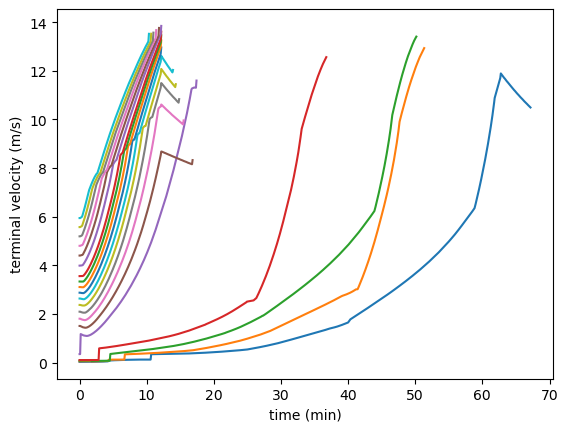

In [5]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    #plt.plot(ncfile['time']/60, p0_ice['horizontal_position'])
    plt.plot(ncfile['time']/60, p0_ice['terminal_velocity'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])

plt.xlabel("time (min)")
plt.ylabel("terminal velocity (m/s)")


Text(0.5, 0, 'time (m)')

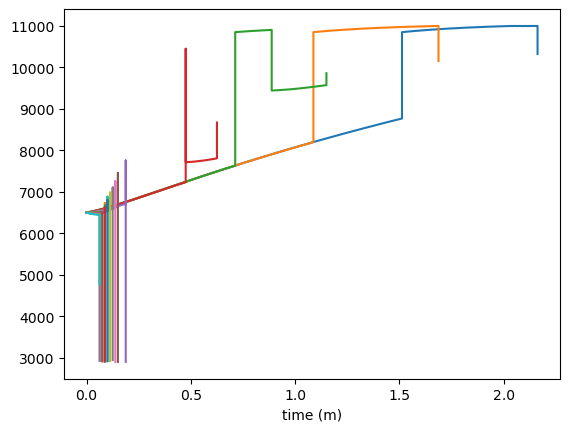

In [ ]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    plt.plot(p0_ice['horizontal_position'], p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])

plt.xlabel("time (m)")

# umax is 2.5 m/s?

In [ ]:
p0_ice

In [24]:
namelist['GENCTOP']

10.5

# v3_4

In [2]:
save_loc_v3_4 = "/gws/ssde/j25a/dcmex/users/ezriab/graupel_model_output/v3_4/"
save_name = 'v3_4_cldtop_cap'
ncfile = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", decode_times=False)
ncfile_envi = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", group="environment", engine="netcdf4",decode_times=False)
ncfile_ice = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", group="ice_particles", engine="netcdf4",decode_times=False)
ncfile_splinter = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", group="splinter_particles", engine="netcdf4",decode_times=False)

# also pull out the variables put into the namelist file
namelist_file = ncfile.attrs["namelist_file"]
with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist)

## pull out relevent functions
sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz

/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


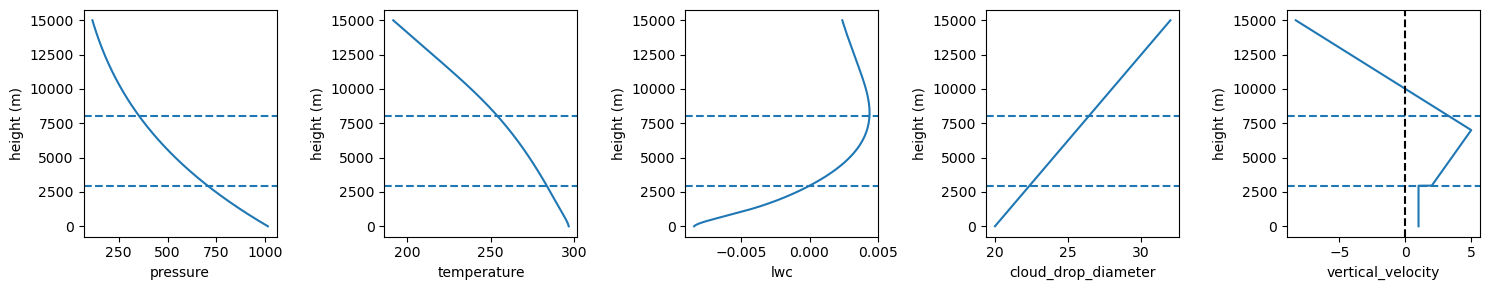

In [3]:
height_vars = ['pressure', 'temperature', 'lwc', 'cloud_drop_diameter', 'vertical_velocity']
zbase = ptz(namelist['pbase']) # height of cloud base (m)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, ax in enumerate(axes):

    ax.plot(ncfile_envi[height_vars[i]], ncfile['height'])

    ax.axhline(
        y=zbase,
        linestyle="--",
        label=f"zbase = {zbase} m")

    ax.axhline(
            y=namelist['CTOP']*1000,
            linestyle="--",
            label=f"CTOP = {namelist['CTOP']} m")

    ax.set_xlabel(height_vars[i])
    ax.set_ylabel("height (m)")
    if height_vars[i] == 'vertical_velocity':
        plt.axvline(x=0, color='black', linestyle='--', label='TWID')


plt.tight_layout()
plt.show()


(0.0, 85.0)

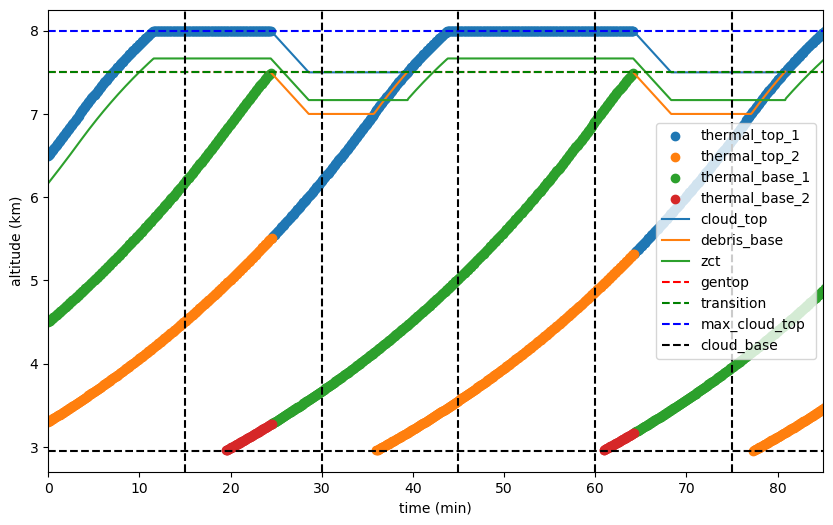

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
#time = np.arange(0, len(thtop1)) * namelist['DELTIM'] / 60

plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_1'], label='thermal_top_1')
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_2'], label='thermal_top_2')
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_1'], label='thermal_base_1')
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_2'], label='thermal_base_2')

plt.plot(ncfile['time']/60, ncfile_envi['cloud_top'], label='cloud_top')
plt.plot(ncfile['time']/60, ncfile_envi['debris_base'], label='debris_base')
zbase = ptz(namelist['pbase']) # height of cloud base (m)
thbase_transition = namelist['CTOP'] - namelist['TDEPTH'] / 4.
GENCTOP = namelist['GENCTOP'] # height of cloud top (m)
CTOP = namelist['CTOP'] # height of cloud top (m)
ZCT = namelist['ZCT'] # height of cloud top (m)
ZCT_values = [v - ZCT for v in ncfile_envi['cloud_top']]
plt.plot(ncfile['time']/60, ZCT_values, label='zct')
plt.axhline(y=GENCTOP, color='r', linestyle='--', label='gentop')
plt.axhline(y=thbase_transition, color='g', linestyle='--', label='transition')
plt.axhline(y=CTOP, color='b', linestyle='--', label='max_cloud_top')
plt.axhline(y=zbase/1000, color='k', linestyle='--', label='cloud_base')

plt.axvline(x=15, color='black', linestyle='--')
plt.axvline(x=30, color='black', linestyle='--')
plt.axvline(x=45, color='black', linestyle='--')
plt.axvline(x=60, color='black', linestyle='--')
plt.axvline(x=75, color='black', linestyle='--')
plt.ylabel("altitude (km)")
plt.xlabel("time (min)")
plt.legend()
#plt.ylim(0, 12)
plt.xlim(0,85)

Text(0, 0.5, 'altitude (km)')

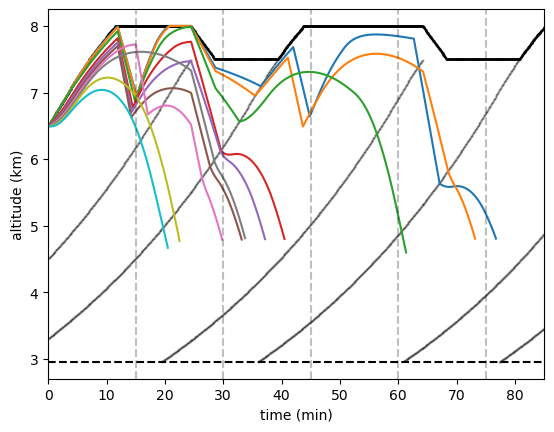

In [5]:
cloud_top = ncfile_envi['cloud_top']

mask_above_cloud = False

for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    altitude = p0_ice['altitude'] / 1000  # km
    if mask_above_cloud:
        # Mask particle altitude above cloud top
        altitude_masked = altitude.where(altitude <= cloud_top)
        plt.plot(ncfile['time'] / 60, altitude_masked)
    else:
        plt.plot(ncfile['time']/60, p0_ice['altitude']/1000)

plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_1'], label='thermal_top_1', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_2'], label='thermal_top_2', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_1'], label='thermal_base_1', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_2'], label='thermal_base_2', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['cloud_top'],color='black', label='cloud_top', s= 0.5)

plt.axvline(x=15, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=30, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=45, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=60, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=75, color='black', linestyle='--', alpha=0.25)


zbase = ptz(namelist['pbase']) # height of cloud base (m)
plt.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base')
plt.xlim(0, 85)
plt.xlabel("time (min)")
plt.ylabel("altitude (km)")

# 22nd oct experiments

In [ ]:
save_loc_v3_4 = "/gws/ssde/j25a/dcmex/users/ezriab/graupel_model_output/22nd_oct_experiments/"
#save_loc_v3_4 = "/gws/ssde/j25a/dcmex/users/ezriab/graupel_model_output/v3_2/"
save_name = '22nd_oct_ctrl'
ncfile = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", decode_times=False)
ncfile_envi = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", group="environment", engine="netcdf4",decode_times=False)
ncfile_ice = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", group="ice_particles", engine="netcdf4",decode_times=False)
try:
    ncfile_splinter = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", group="splinter_particles", engine="netcdf4",decode_times=False)
    print("Splinters!!")
except:
    print("No splinter particles found.")

# also pull out the variables put into the namelist file
'''
namelist_file = ncfile.attrs["namelist_file"]
with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist)
'''
## pull out relevent functions
sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz

No splinter particles found.


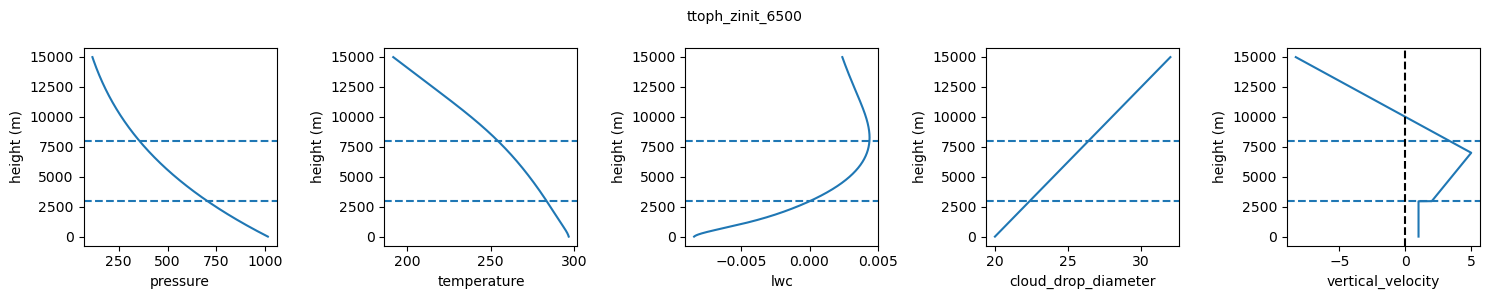

In [3]:
height_vars = ['pressure', 'temperature', 'lwc', 'cloud_drop_diameter', 'vertical_velocity']
zbase = ptz(namelist['pbase']) # height of cloud base (m)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, ax in enumerate(axes):

    ax.plot(ncfile_envi[height_vars[i]], ncfile['height'])

    ax.axhline(
        y=zbase,
        linestyle="--",
        label=f"zbase = {zbase} m")

    ax.axhline(
            y=namelist['CTOP']*1000,
            linestyle="--",
            label=f"CTOP = {namelist['CTOP']} m")

    ax.set_xlabel(height_vars[i])
    ax.set_ylabel("height (m)")
    if height_vars[i] == 'vertical_velocity':
        plt.axvline(x=0, color='black', linestyle='--', label='TWID')

plt.suptitle(f"{save_name}", fontsize=10)
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'ttoph_zinit_6500')

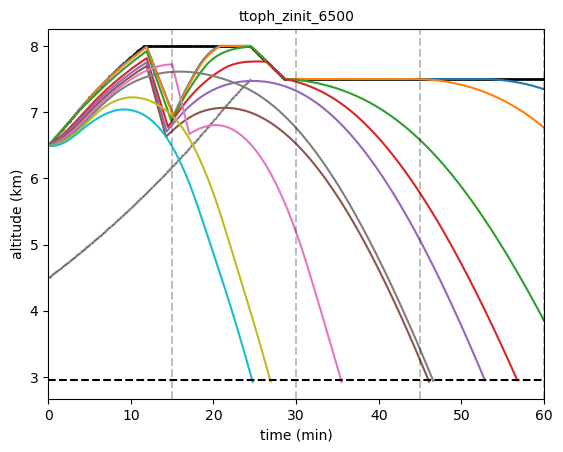

In [4]:
cloud_top = ncfile_envi['cloud_top']

mask_above_cloud = False

for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    altitude = p0_ice['altitude'] / 1000  # km
    if mask_above_cloud:
        # Mask particle altitude above cloud top
        altitude_masked = altitude.where(altitude <= cloud_top)
        plt.plot(ncfile['time'] / 60, altitude_masked)
    else:
        plt.plot(ncfile['time']/60, p0_ice['altitude']/1000)
'''
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_1'], label='thermal_top_1', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_2'], label='thermal_top_2', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_2'], label='thermal_base_2', s= 0.5, color='black', alpha=0.25)
'''
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_1'], label='thermal_base_1', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['cloud_top'],color='black', label='cloud_top', s= 0.5)
plt.axvline(x=15, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=30, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=45, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=60, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=75, color='black', linestyle='--', alpha=0.25)


zbase = ptz(namelist['pbase']) # height of cloud base (m)
plt.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base')
plt.xlim(0, 60)
plt.xlabel("time (min)")
plt.ylabel("altitude (km)")
plt.title(f"{save_name}", fontsize=10)


Text(0.5, 1.0, 'ttoph_zinit_6500')

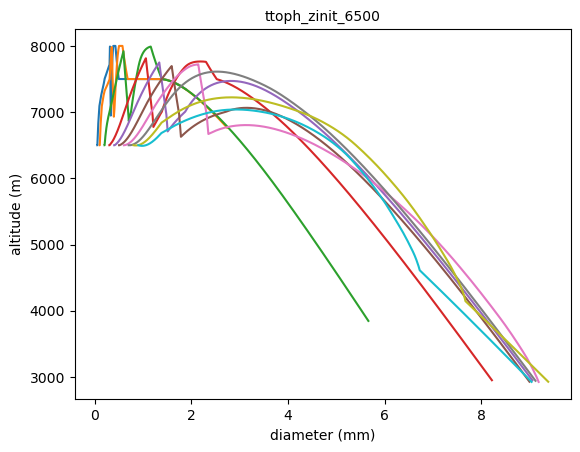

In [5]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    #plt.plot(ncfile['time']/60, p0_ice['diameter']*1000)
    plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])

plt.xlabel("diameter (mm)")
plt.ylabel("altitude (m)")
plt.title(f"{save_name}", fontsize=10)


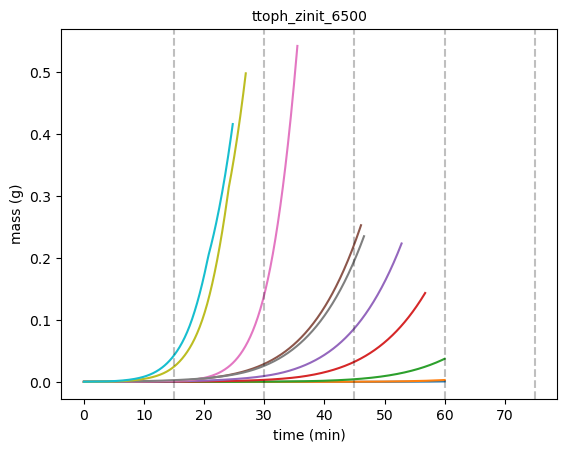

In [6]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    plt.plot(ncfile['time']/60, p0_ice['mass']*1000)
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])

plt.xlabel("time (min)")
plt.ylabel("mass (g)")
plt.title(f"{save_name}", fontsize=10)
plt.axvline(x=15, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=30, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=45, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=60, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=75, color='black', linestyle='--', alpha=0.25)


Text(0.5, 1.0, '22nd_oct_ctrl')

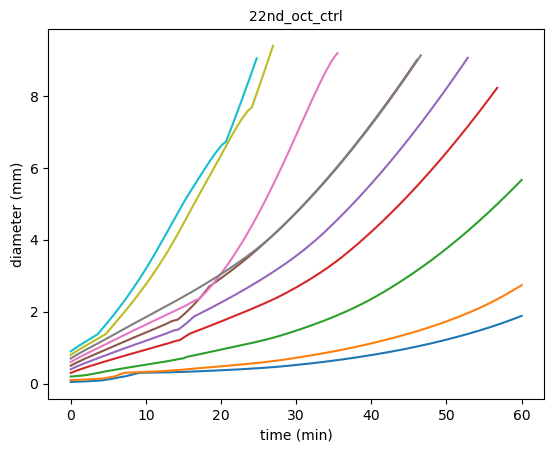

In [8]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    #plt.plot(ncfile['time']/60, p0_ice['diameter']*1000)
    plt.plot(ncfile['time']/60, p0_ice['diameter']*1000)


plt.ylabel("diameter (mm)")
plt.xlabel("time (min)")
plt.title(f"{save_name}", fontsize=10)


Text(0.5, 0, 'horizontal position (m)')

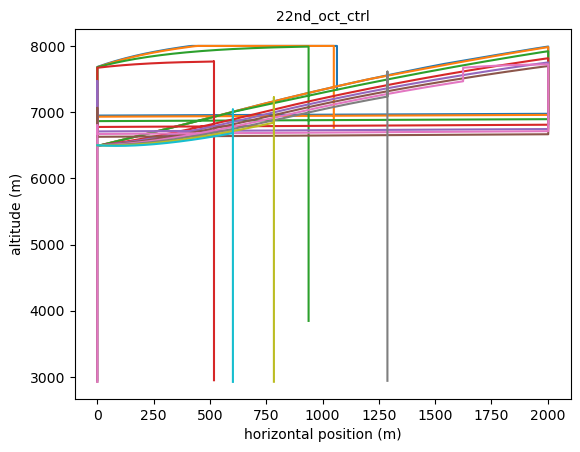

In [11]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    #plt.plot(ncfile['time']/60, p0_ice['diameter']*1000)
    plt.plot(p0_ice['horizontal_position']*1000, p0_ice['altitude'])



plt.title(f"{save_name}", fontsize=10)
plt.ylabel("altitude (m)")
plt.xlabel("horizontal position (m)")

In [6]:
p0_ice

<xarray.Dataset> Size: 26kB
Dimensions:              (time: 721)
Dimensions without coordinates: time
Data variables:
    diameter             (time) float32 3kB 0.0009 0.000911 ... nan nan
    density              (time) float32 3kB ...
    mass                 (time) float32 3kB ...
    surface_temperature  (time) float32 3kB ...
    terminal_velocity    (time) float32 3kB ...
    altitude             (time) float32 3kB ...
    horizontal_position  (time) float32 3kB ...
    horizontal_wind      (time) float32 3kB ...
    concentration        (time) float32 3kB ...

# 30th set up?

In [2]:
save_loc_v3_4 = "/gws/ssde/j25a/dcmex/users/ezriab/graupel_model_output/30th/"
#save_loc_v3_4 = "/gws/ssde/j25a/dcmex/users/ezriab/graupel_model_output/v3_2/"
save_name = '30th_1'
ncfile = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", decode_times=False)
ncfile_envi = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", group="environment", engine="netcdf4",decode_times=False)
ncfile_ice = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", group="ice_particles", engine="netcdf4",decode_times=False)
try:
    ncfile_splinter = xr.open_dataset(f"{save_loc_v3_4}{save_name}.nc", group="splinter_particles", engine="netcdf4",decode_times=False)
    print("Splinters!!")
except:
    print("No splinter particles found.")

# also pull out the variables put into the namelist file

namelist_file = ncfile.attrs["namelist_file"]
with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist)

## pull out relevent functions
sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz

/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


No splinter particles found.


In [3]:
ncfile_ice

<xarray.Dataset> Size: 260kB
Dimensions:              (particle: 10, time: 721)
Dimensions without coordinates: particle, time
Data variables:
    diameter             (particle, time) float32 29kB ...
    density              (particle, time) float32 29kB ...
    mass                 (particle, time) float32 29kB ...
    surface_temperature  (particle, time) float32 29kB ...
    terminal_velocity    (particle, time) float32 29kB ...
    altitude             (particle, time) float32 29kB ...
    horizontal_position  (particle, time) float32 29kB ...
    horizontal_wind      (particle, time) float32 29kB ...
    concentration        (particle, time) float32 29kB ...

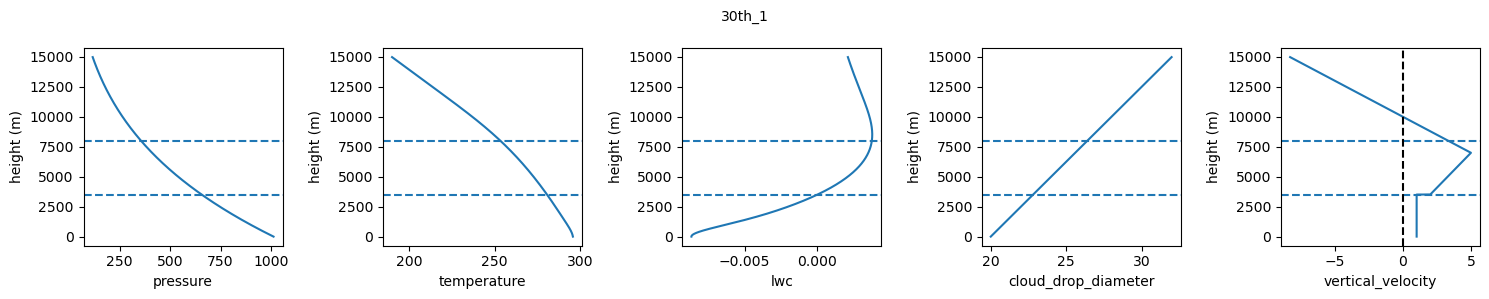

In [3]:
height_vars = ['pressure', 'temperature', 'lwc', 'cloud_drop_diameter', 'vertical_velocity']
zbase = ptz(namelist['pbase']) # height of cloud base (m)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, ax in enumerate(axes):

    ax.plot(ncfile_envi[height_vars[i]], ncfile['height'])

    ax.axhline(
        y=zbase,
        linestyle="--",
        label=f"zbase = {zbase} m")

    ax.axhline(
            y=namelist['CTOP']*1000,
            linestyle="--",
            label=f"CTOP = {namelist['CTOP']} m")

    ax.set_xlabel(height_vars[i])
    ax.set_ylabel("height (m)")
    if height_vars[i] == 'vertical_velocity':
        plt.axvline(x=0, color='black', linestyle='--', label='TWID')

plt.suptitle(f"{save_name}", fontsize=10)
plt.tight_layout()
plt.show()

Text(0.5, 1.0, '30th_1')

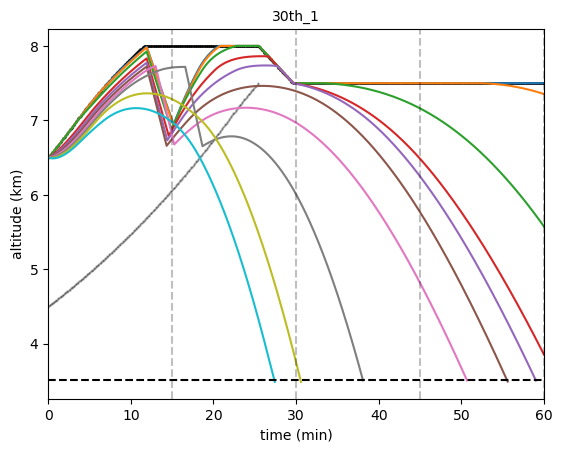

In [5]:
cloud_top = ncfile_envi['cloud_top']

mask_above_cloud = False

for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    altitude = p0_ice['altitude'] / 1000  # km
    if mask_above_cloud:
        # Mask particle altitude above cloud top
        altitude_masked = altitude.where(altitude <= cloud_top)
        plt.plot(ncfile['time'] / 60, altitude_masked)
    else:
        plt.plot(ncfile['time']/60, p0_ice['altitude']/1000)
'''
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_1'], label='thermal_top_1', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_top_2'], label='thermal_top_2', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_2'], label='thermal_base_2', s= 0.5, color='black', alpha=0.25)
'''
plt.scatter(ncfile['time']/60, ncfile_envi['thermal_base_1'], label='thermal_base_1', s= 0.5, color='black', alpha=0.25)
plt.scatter(ncfile['time']/60, ncfile_envi['cloud_top'],color='black', label='cloud_top', s= 0.5)
plt.axvline(x=15, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=30, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=45, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=60, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=75, color='black', linestyle='--', alpha=0.25)


zbase = ptz(namelist['pbase']) # height of cloud base (m)
plt.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base')
plt.xlim(0, 60)
plt.xlabel("time (min)")
plt.ylabel("altitude (km)")
plt.title(f"{save_name}", fontsize=10)


Text(0.5, 1.0, '30th_1')

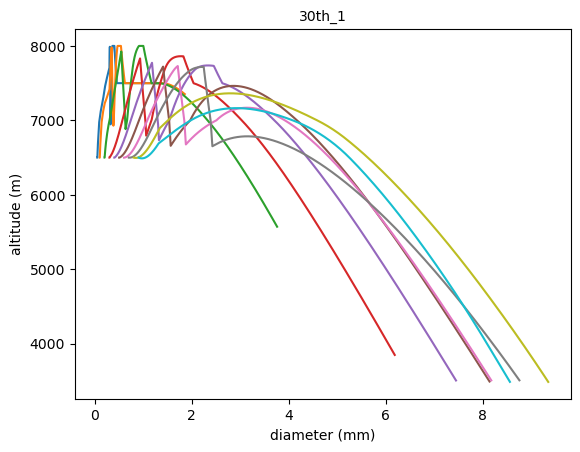

In [6]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])

plt.xlabel("diameter (mm)")
plt.ylabel("altitude (m)")
plt.title(f"{save_name}", fontsize=10)


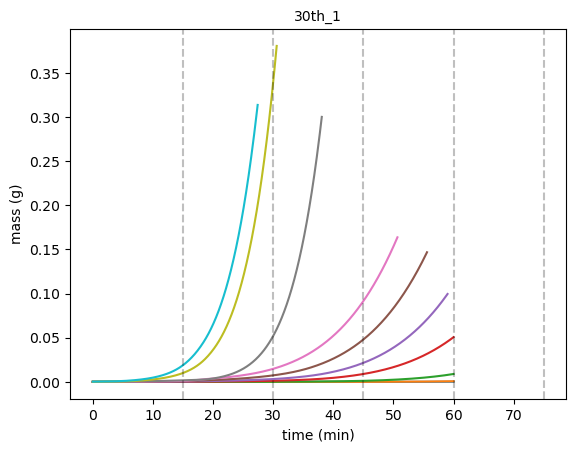

In [7]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    plt.plot(ncfile['time']/60, p0_ice['mass']*1000)

plt.xlabel("time (min)")
plt.ylabel("mass (g)")
plt.title(f"{save_name}", fontsize=10)
plt.axvline(x=15, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=30, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=45, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=60, color='black', linestyle='--', alpha=0.25)
plt.axvline(x=75, color='black', linestyle='--', alpha=0.25)


Text(0.5, 1.0, '30th_1')

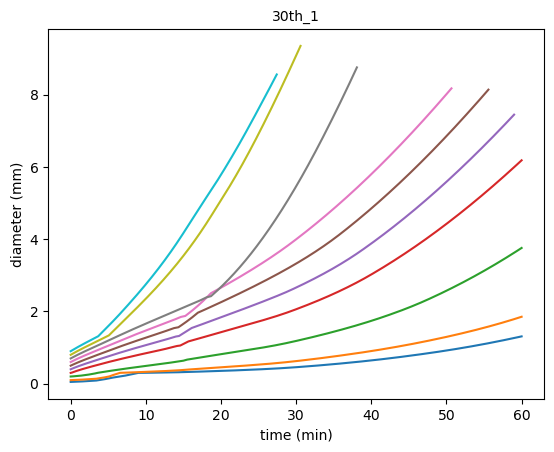

In [8]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    plt.plot(ncfile['time']/60, p0_ice['diameter']*1000)


plt.ylabel("diameter (mm)")
plt.xlabel("time (min)")
plt.title(f"{save_name}", fontsize=10)


Text(0.5, 0, 'horizontal position (m)')

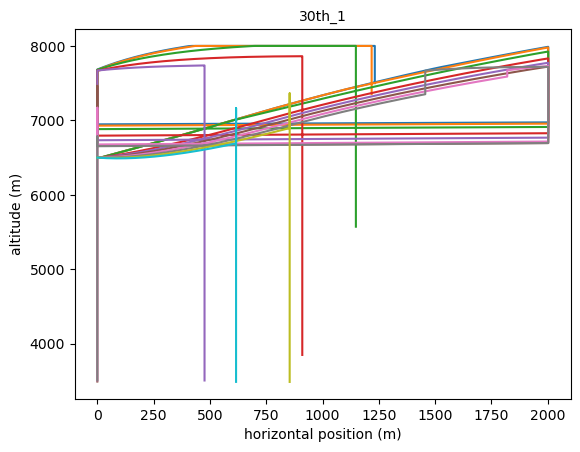

In [9]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    plt.plot(p0_ice['horizontal_position']*1000, p0_ice['altitude'])



plt.title(f"{save_name}", fontsize=10)
plt.ylabel("altitude (m)")
plt.xlabel("horizontal position (m)")